# 11. Who wins, DMRG or a quantum computer?

The question: for the frustrated J1-J2 Heisenberg model on a cylinder of width $W$,

$$
H = J_1 \sum_{\langle ij\rangle} \mathbf S_i\cdot\mathbf S_j + J_2 \sum_{\langle\langle ij\rangle\rangle} \mathbf S_i\cdot\mathbf S_j,
\qquad J_2/J_1 = 0.5,
$$

how long does it take to get the ground-state energy to $\pm 0.01\,J_1$, with DMRG on a classical computer and
with phase estimation on a fault-tolerant quantum computer? At $J_2/J_1 = 0.5$ quantum Monte Carlo has a sign
problem, so DMRG is the classical method to beat.

In [1]:
import matplotlib.pyplot as plt

from dmrg_from_scratch import j1j2_cylinder
from dmrg_from_scratch.resources import chi_needed, dmrg_seconds, run_ladder
from dmrg_from_scratch.resources import crossover, load_ladders
from dmrg_from_scratch import ground_state
from dmrg_from_scratch.resources import qpe_cost

## The quantum price in one call

Give `qpe_cost` a Hamiltonian and a precision. It counts the gates of qubitized phase estimation with
`pennylane.estimator` and converts them to time at 170 µs per Toffoli (one magic-state factory).

In [2]:
H = j1j2_cylinder(4)  # 4 x 4 cylinder, 16 spins
q = qpe_cost(H, eps=0.01)
print(f"{q['toffoli']:.2e} Toffolis on {q['logical_qubits']} logical qubits: {q['seconds'] / 60:.0f} minutes")

3.41e+06 Toffolis on 124 logical qubits: 12 minutes


## The classical price, live

Run DMRG at a few bond dimensions $\chi$, see how the error falls, and solve for the $\chi$ that reaches
$0.01$. Here the cylinder is small enough to compare with exact diagonalization.

In [3]:
E0, _ = ground_state(H)
runs = run_ladder(H, chis=(4, 8, 16), n_sweeps=3)
chi = chi_needed(runs, eps=0.01, E_ref=E0)
print(f"DMRG needs chi = {chi:.0f}: {dmrg_seconds(runs, chi):.1e} seconds at 1e12 flop/s")

DMRG needs chi = 16: 4.5e-03 seconds at 1e12 flop/s


On 16 spins DMRG wins by five orders of magnitude. That is the first lesson: a quantum computer has a large
constant overhead (error correction makes every gate slow), and it only pays off where the classical cost has
exploded.

## Where the curves cross

DMRG's cost grows exponentially with the width (the entanglement it must store grows with $W$), the quantum cost
only polynomially. Precomputed DMRG runs up to the 8 x 8 cylinder, extrapolated (`python scripts/make_results.py`,
about two hours on 4 cores):

quantum wins from W = 9


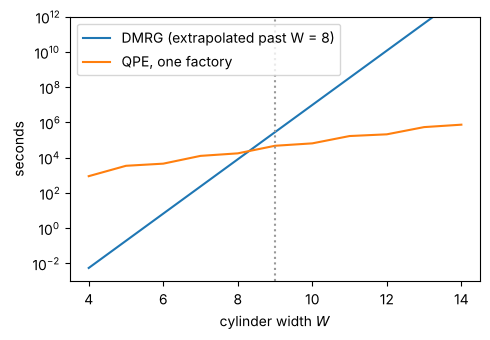

In [4]:
r = crossover(load_ladders(), widths=range(4, 15))
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogy(r["widths"], r["classical"], label="DMRG (extrapolated past W = 8)")
ax.semilogy(r["widths"], r["quantum"], label="QPE, one factory")
ax.axvline(r["W_star"], color="0.6", ls=":")
ax.set(xlabel="cylinder width $W$", ylabel="seconds", ylim=(1e-3, 1e12))
ax.legend()
fig.tight_layout()
print("quantum wins from W =", r["W_star"])

## The notebooks

| Notebook | What you learn |
|---|---|
| [12 · The classical price](12_classical_price.ipynb) | why DMRG cost is set by entanglement, the bond dimension needed vs width, flops and seconds |
| [13 · The quantum price](13_quantum_price.ipynb) | block encodings and the one-norm $\lambda$, walk calls, Toffolis, logical qubits, wall clock |
| [14 · The hidden cost, and the crossover](14_overlap_and_crossover.ipynb) | why phase estimation needs a good starting state, using DMRG to make one, and the crossover with error bars |